# 🚢 Pandas — Niveau 2 : ADAPTER (dataset Titanic)

**Principe de la séance** : plus d'exemple à recopier. Pour chaque question, tu as :
- une **consigne** (ce qu'il faut obtenir) ;
- une boîte **🧰 Outils** qui nomme les méthodes utiles.

À toi de les **adapter** à ces nouvelles données, en t'appuyant sur ce que tu as fait avec Iris. Les seules notions vraiment nouvelles (valeurs manquantes, texte) sont décrites dans un encadré **📘 Nouveau**, sans exemple tout fait.

> 💡 Bloqué·e ? Dans Jupyter, `Shift + Tab` sur une méthode affiche sa documentation ; `help(pd.Series.fillna)` aussi. Et ton notebook Iris reste ta meilleure antisèche.

### Le jeu de données
Les passagers du Titanic (version Kaggle *Titanic – Machine Learning from Disaster*, fichier `train.csv`) : 891 passagers, dont on sait s'ils ont survécu au naufrage du 15 avril 1912.

| Colonne | Signification |
|---|---|
| `PassengerId` | identifiant |
| `Survived` | 1 = a survécu, 0 = décédé |
| `Pclass` | classe du billet : 1, 2 ou 3 |
| `Name`, `Sex`, `Age` | nom (avec le titre : Mr, Mrs…), sexe, âge en années |
| `SibSp` | nombre de frères/sœurs + conjoint·e à bord |
| `Parch` | nombre de parents + enfants à bord |
| `Ticket`, `Fare` | numéro et prix du billet (en livres sterling) |
| `Cabin` | numéro de cabine (ex. `C85` : pont C) |
| `Embarked` | port d'embarquement : C = Cherbourg, Q = Queenstown, S = Southampton |

### 🎯 Question fil rouge
**Qui a survécu au naufrage ?** Toutes les étapes de ce notebook servent à y répondre dans la conclusion.

### 🧭 Mode d'emploi

- Chaque exercice ✏️ a une **consigne** (ce qu'il faut obtenir), une boîte **🧰 Outils** (les méthodes utiles, sans exemple tout fait) et un **✅ résultat attendu** : compare ton résultat avant de passer à la suite. Quand tu n'obtiens pas le ✅, cherche l'erreur avant de continuer : beaucoup d'exercices réutilisent les colonnes des précédents.
- Pour afficher **plusieurs tableaux** dans une même cellule, mets chacun dans `display(...)` (c'est plus lisible que `print` pour un tableau).
- Quand une consigne pose une **question**, réponds dans la cellule de texte « Ma réponse » juste en dessous : double-clique dessus, écris, puis `Maj + Entrée`.
- Le tableau des erreurs fréquentes du notebook Iris reste valable. Le plus fréquent ici : un `&` sans parenthèses autour de chaque condition. Nouvelle erreur possible : `SyntaxError: invalid decimal literal` quand on écrit `* 100.round(1)` ; il faut des parenthèses autour du calcul, `(… * 100).round(1)`.

> 📘 **Nouveau — réaffecter le résultat**
> La plupart des méthodes pandas (`fillna`, `replace`, `merge`, `drop`…) **ne modifient pas** le tableau : elles renvoient un **nouveau** résultat. Si on ne le range pas quelque part, il est perdu, sans aucun message d'erreur.
> - Pour modifier **une colonne** : `titanic["col"] = titanic["col"].fillna(...)`
> - Pour modifier **tout le tableau** : `titanic = titanic.merge(...)`
>
> Réflexe : quand un ✅ n'est pas atteint alors que ton code « a l'air juste », vérifie d'abord que tu as bien réaffecté le résultat.
- Tout s'est mélangé ? *Noyau > Redémarrer et tout exécuter*.

## 0. Chargement
On lit le fichier CSV directement depuis une copie publique. Si tu n'as pas internet, télécharge `train.csv` sur Kaggle, place-le à côté du notebook et remplace l'URL par `"train.csv"`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(URL)

## 1. Premier contact

### ✏️ 1.1 — Premier aperçu

Affiche trois choses, dans la même cellule :
1. la **taille** du tableau (nombre de lignes, nombre de colonnes) ;
2. **5 lignes tirées au hasard** (et non les 5 premières) ;
3. le **type** de chaque colonne.

Comme une cellule n'affiche que sa dernière ligne, mets les deux premiers résultats dans `display(...)` ou `print(...)`.

🧰 **Outils** : `shape` · `sample(5)` · `dtypes`

✅ **Résultat attendu** : `(891, 12)` ; les colonnes de texte (`Name`, `Sex`…) ont le type `str` ou `object`.

In [2]:
# Écris ton code ici
display(titanic)
display(titanic.shape)
display(titanic.sample(5))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


(891, 12)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
376,377,1,3,"Landergren, Miss. Aurora Adelia",female,22.0,0,0,C 7077,7.2500,NaN,S
40,41,0,3,"Ahlin, Mrs. Johan (Johanna Persdotter Larsson)",female,40.0,1,0,7546,9.4750,NaN,S
649,650,1,3,"Stanley, Miss. Amy Zillah Elsie",female,23.0,0,0,CA. 2314,7.5500,NaN,S
627,628,1,1,"Longley, Miss. Gretchen Fiske",female,21.0,0,0,13502,77.9583,D9,S
157,158,0,3,"Corn, Mr. Harry",male,30.0,0,0,SOTON/OQ 392090,8.0500,NaN,S


### ✏️ 1.2 — Statistiques descriptives

Affiche les statistiques des colonnes **numériques**, puis celles des colonnes de **texte**, chacune dans un `display(...)`.

Puis lis les deux tableaux pour répondre dans la cellule de texte en dessous :
- quel est l'**âge moyen** des passagers ?
- quel est le **prix de billet le plus élevé** ?
- quel est le **port d'embarquement le plus fréquent**, et combien de passagers y sont montés ?

🧰 **Outils** : `describe()` pour les nombres · `describe(exclude="number")` pour le texte : la ligne `top` donne la valeur la plus fréquente, `freq` son nombre d'apparitions

✅ **Résultat attendu** : un âge moyen proche de 30 ans.

In [40]:
# Écris ton code ici
display(titanic.describe())
display(titanic.describe(exclude="number"))

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize,TicketGroupSize,FarePerPerson
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.066409,0.523008,0.381594,32.204208,1.904602,1.787879,17.788989
std,257.353842,0.486592,0.836071,13.244532,1.102743,0.806057,49.693429,1.613459,1.361142,21.218157
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400,1.000000,1.000000,7.762500
50%,446.000000,0.000000,3.000000,26.000000,0.000000,0.000000,14.454200,1.000000,1.000000,8.850000
75%,668.500000,1.000000,3.000000,37.000000,1.000000,0.000000,31.000000,2.000000,2.000000,24.288200
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,11.000000,7.000000,221.779200


,Name,Sex,Ticket,Cabin,Embarked,HasCabin,Deck,AgeManquant,Alone,title,AgeGroup,ville,pays
count,891,891,891,204,891,891,891,891,891,891,891,891,891
unique,891,2,681,147,3,2,9,2,2,5,5,3,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S,False,Inconnu,True,True,Mr,JeuneAdulte,Southampton,Angleterre
freq,1,577,7,4,646,687,687,714,537,517,417,646,646


**Mes réponses** : âge moyen = … ans · prix le plus élevé = … £ · port le plus fréquent = … (… passagers)

### ✏️ 1.3 — Taux de survie et répartition par sexe

Calcule :
1. le **taux de survie global**, en pourcentage ;
2. la **proportion d'hommes et de femmes** à bord.

Astuce : la colonne `Survived` vaut 1 (survie) ou 0 (décès). Sa **moyenne** est donc directement la proportion de survivants : 0.38 veut dire 38 %.

🧰 **Outils** : `mean()` · `value_counts(normalize=True)` (donne des proportions au lieu de nombres)

✅ **Résultat attendu** : environ **38 %** de survivants ; environ **65 %** d'hommes et **35 %** de femmes.

In [4]:
# Écris ton code ici
display((titanic["Survived"].value_counts(normalize=True) * 100).round(2))
display((titanic["Survived"].mean() * 100).round(2))
((titanic["Sex"].value_counts(normalize=True) * 100).round(2))

Survived
0    61.62
1    38.38
Name: proportion, dtype: float64

np.float64(38.38)

Sex
male      64.76
female    35.24
Name: proportion, dtype: float64

## 2. Les valeurs manquantes

> 📘 **Nouveau — les valeurs manquantes**
> Une case vide dans le CSV devient `NaN` (*Not a Number*) dans pandas.
> - `df.isna()` renvoie un tableau de `True` (manquant) / `False` ; combiné à `.sum()` il compte, combiné à `.mean()` il donne une proportion.
> - `serie.fillna(valeur)` remplace les `NaN` par une valeur.
> - `df.dropna(subset=["col"])` supprime les lignes où `col` est manquante.
> - `serie.mode()` renvoie la (ou les) valeur(s) la plus fréquente(s), sous forme de **Series** : pour obtenir la valeur elle-même, écris `serie.mode()[0]`. `serie.median()` donne la médiane.
>
> Avant de remplir, on se demande toujours : *pourquoi la donnée manque-t-elle, et qu'est-ce qui est le plus raisonnable ?*

### ✏️ 2.1 — Mesurer les valeurs manquantes

Pour chaque colonne, affiche le **pourcentage** de valeurs manquantes, arrondi à 1 chiffre, **trié du plus grand au plus petit**.

Puis réponds en dessous : quelles colonnes posent problème ?

🧰 **Outils** : `isna()` · `mean()` (proportion de `True`) · `* 100` · `round(1)` · `sort_values(ascending=False)`

✅ **Résultat attendu** : `Cabin` ≈ **77,1 %**, `Age` ≈ **19,9 %**, `Embarked` ≈ **0,2 %**, toutes les autres à 0.

In [5]:
# Écris ton code ici
display((titanic.isna().mean() * 100).round(1).sort_values(ascending=False))


Cabin          77.1
Age            19.9
Embarked        0.2
PassengerId     0.0
Name            0.0
Pclass          0.0
Survived        0.0
Sex             0.0
Parch           0.0
SibSp           0.0
Fare            0.0
Ticket          0.0
dtype: float64

**Ma réponse** : …

### ✏️ 2.2 — Remplir les 2 ports manquants

Dans `Embarked`, il ne manque que 2 valeurs. Remplace-les par le **port le plus fréquent**, puis **vérifie** qu'il n'en manque plus.

⚠️ **Deux pièges**, qui donnent tous les deux 2 valeurs encore manquantes, **sans aucun message d'erreur** :
- `mode()` renvoie une **Series** (il peut y avoir plusieurs valeurs à égalité), pas une valeur simple. Pour obtenir le port lui-même, écris `mode()[0]`.
- `fillna(...)` ne modifie pas la colonne : il faut **réaffecter** le résultat, `titanic["Embarked"] = titanic["Embarked"].fillna(...)` (voir l'encadré 📘 « réaffecter » au début).

🧰 **Outils** : `mode()[0]` · `fillna(...)` · `isna().sum()`

✅ **Résultat attendu** : la vérification affiche **0**.

In [6]:
# Écris ton code ici
display((titanic["Embarked"].value_counts(normalize=True, dropna=False) * 100).round(2))

titanic["Embarked"] = titanic["Embarked"].fillna(titanic["Embarked"].mode()[0])

(titanic["Embarked"].value_counts(normalize=True, dropna=False) * 100).round(2)


Embarked
S      72.28
C      18.86
Q       8.64
NaN     0.22
Name: proportion, dtype: float64

Embarked
S    72.50
C    18.86
Q     8.64
Name: proportion, dtype: float64

### ✏️ 2.3 — La colonne Cabin

77 % des cabines sont inconnues : on ne peut pas les deviner. On va plutôt **garder l'information « cabine connue ou non »**.
- a) Crée une colonne `HasCabin` : `True` si la cabine est connue.
- b) Crée une colonne `Deck` : la **première lettre** de la cabine, qui correspond au pont du navire (`"C85"` → `"C"`), et `"Inconnu"` quand la cabine est absente.
- c) Calcule le taux de survie selon `HasCabin`, et réponds en dessous : les passagers dont la cabine est connue ont-ils plus survécu ?

🧰 **Outils** : `notna()` (contraire de `isna()`) · `.str[0]` (premier caractère d'un texte) · `fillna("Inconnu")` · `groupby` · `mean`

✅ **Résultat attendu** : `Deck` vaut `"Inconnu"` pour **687** passagers ; taux de survie ≈ **67 %** avec cabine connue contre ≈ **30 %** sans.

In [7]:
# Écris ton code ici
titanic["HasCabin"] = titanic["Cabin"].notna()
display(titanic["HasCabin"])

titanic["Deck"] = titanic["Cabin"].str[0].fillna("Inconnu")
display(titanic["Deck"])

display((titanic.groupby("HasCabin")["Survived"].mean() * 100).round(2))



0      False
1       True
2      False
3       True
4      False
       ...  
886    False
887     True
888    False
889     True
890    False
Name: HasCabin, Length: 891, dtype: bool

0      Inconnu
1            C
2      Inconnu
3            C
4      Inconnu
        ...   
886    Inconnu
887          B
888    Inconnu
889          C
890    Inconnu
Name: Deck, Length: 891, dtype: str

HasCabin
False    29.99
True     66.67
Name: Survived, dtype: float64

**Ma réponse** : …

> 📘 **Nouveau — `transform`**
> `df.groupby("A")["B"].transform("median")` calcule la médiane de `B` **pour chaque groupe** de `A`, puis la **recopie sur chaque ligne** du groupe. Le résultat a donc la même longueur que le tableau d'origine : on peut s'en servir directement dans un `fillna`.
> Avec `transform("size")`, on obtient de la même façon le **nombre de lignes** de chaque groupe, recopié sur chaque ligne (utile en 4.4).

### ✏️ 2.4 — Remplir les âges manquants par groupe

20 % des âges manquent. Les remplacer tous par l'âge moyen serait grossier : les passagers de 1re classe sont plus âgés, les femmes plus jeunes…
- a) **Avant** de remplir, crée une colonne `AgeManquant` (`True`/`False`) pour garder la trace des âges qui étaient manquants.
- b) Affiche l'**âge médian par classe et par sexe** avec `display(...)`, pour voir les valeurs qui vont servir à remplir.
- c) Remplace chaque âge manquant par l'**âge médian des passagers de même classe et de même sexe**. Lis l'encadré 📘 `transform` juste au-dessus : il fait exactement ce calcul.
- d) Vérifie qu'il ne reste aucun âge manquant.

🧰 **Outils** : `isna()` · `groupby(["Pclass", "Sex"])["Age"].median()` (une **liste** de colonnes) · `transform("median")` · `fillna(...)`

✅ **Résultat attendu** : la vérification affiche **0** ; par exemple, l'âge médian des hommes de 1re classe est **40** ans.

In [8]:
# Écris ton code ici
titanic["AgeManquant"] = titanic["Age"].notna()
print(titanic["AgeManquant"])

display(titanic.groupby(["Pclass", "Sex"])["Age"].median())

titanic["Age"] = titanic["Age"].fillna(
    titanic.groupby("Pclass")["Age"].transform("median")
)
print(titanic["Age"].isna().sum())

0       True
1       True
2       True
3       True
4       True
       ...  
886     True
887     True
888    False
889     True
890     True
Name: AgeManquant, Length: 891, dtype: bool


Pclass  Sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: Age, dtype: float64

0


## 3. Sélectionner et filtrer

### ✏️ 3.1 — Les enfants de 3e classe

Affiche le **nom**, l'**âge** et le **prix du billet** des **enfants de strictement moins de 12 ans** (`< 12`) voyageant en **3e classe**.

Puis affiche combien ils sont, et leur **taux de survie**.

Astuce : range d'abord la condition dans une variable, `masque = (…) & (…)`. Tu pourras la réutiliser pour les trois calculs. Pour le taux de survie, sélectionne la colonne `Survived` avec le même masque : `titanic.loc[masque, "Survived"]`. Le tableau des 3 colonnes affichées ne contient pas `Survived`.

🧰 **Outils** : deux conditions combinées avec `&` (et des parenthèses !) · `loc[masque, [colonnes]]` · `sum()` ou `len` · `mean`

✅ **Résultat attendu** : **47** enfants, taux de survie ≈ **0.40** (40 %).

In [9]:
# Écris ton code ici
masque = (titanic["Age"] < 12) & (titanic["Pclass"] == 3)
display(titanic[["Name", "Age", "Fare"]])

print(titanic[masque].shape[0])
print(f"Le nombre de survivant : {titanic.loc[masque, "Survived"].sum()}")
print(f" le % d'enfant suirvant est : {titanic.loc[masque, "Survived"].sum() / titanic[masque].shape[0] * 100:.2f}")

,Name,Age,Fare
0,"Braund, Mr. Owen Harris",22.0,7.2500
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,71.2833
2,"Heikkinen, Miss. Laina",26.0,7.9250
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,53.1000
4,"Allen, Mr. William Henry",35.0,8.0500
...,...,...,...
886,"Montvila, Rev. Juozas",27.0,13.0000
887,"Graham, Miss. Margaret Edith",19.0,30.0000
888,"Johnston, Miss. Catherine Helen ""Carrie""",24.0,23.4500
889,"Behr, Mr. Karl Howell",26.0,30.0000


47
Le nombre de survivant : 19
 le % d'enfant suirvant est : 40.43


### ✏️ 3.2 — Femmes de 1re classe contre hommes de 3e classe

Calcule le **taux de survie des femmes de 1re classe**, puis celui des **hommes de 3e classe**, et affiche les deux.

🧰 **Outils** : masques combinés · `mean` · ou bien `query("Sex == 'male' and Pclass == 3")`

✅ **Résultat attendu** : environ **97 %** pour les femmes de 1re classe contre **14 %** pour les hommes de 3e classe.

In [10]:
# Écris ton code ici

SurvivantsFemme = (titanic.query("Sex == 'female' and Pclass == 1 and Survived == 1").shape[0])
SurvivantsHomme = (titanic.query("Sex == 'male' and Pclass == 3 and Survived == 1").shape[0])
PrctSurvivantsFemme = SurvivantsFemme / titanic.query("Sex == 'female' and Pclass == 1").shape[0]
PrctSurvivantsHomme = SurvivantsHomme / titanic.query("Sex == 'male' and Pclass == 3").shape[0]
print(f"Nombre de survivantes Femme : {SurvivantsFemme}")
print(f"Nombre de survivants Homme : {SurvivantsHomme}")
print(f"le % de survivante Femme : {PrctSurvivantsHomme * 100:.1f}")
print(f"le % de survivant homme : {PrctSurvivantsFemme * 100:.1f}")

#print(f"le nombre de survivant homme de 3eme classe est : {}")

Nombre de survivantes Femme : 91
Nombre de survivants Homme : 47
le % de survivante Femme : 13.5
le % de survivant homme : 96.8


### ✏️ 3.3 — Les billets les plus chers

Affiche les **5 billets les plus chers**, avec pour chacun : le nom, la classe, le prix, le **numéro de ticket** et la survie.

Puis réponds en dessous : **que remarques-tu sur les prix et les numéros de ticket ?** (Cette remarque te servira en 4.4.)

🧰 **Outils** : `sort_values(..., ascending=False)` · sélection de plusieurs colonnes `[[...]]` · `head(5)`

✅ **Résultat attendu** : le prix le plus élevé est **512,33 £**.

In [11]:
# Écris ton code ici

display(titanic.nlargest(5, "Fare")[["Name", "Pclass", "Fare", "Ticket", "Survived"]])

,Name,Pclass,Fare,Ticket,Survived
258,"Ward, Miss. Anna",1,512.3292,PC 17755,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,PC 17755,1
737,"Lesurer, Mr. Gustave J",1,512.3292,PC 17755,1
27,"Fortune, Mr. Charles Alexander",1,263.0000,19950,0
88,"Fortune, Miss. Mabel Helen",1,263.0000,19950,1


**Ma réponse** : …

### ✏️ 3.4 — Survie selon le port d'embarquement

Compare le taux de survie des passagers montés à **Cherbourg ou Queenstown** (codes `C` et `Q`) à celui des passagers montés à **Southampton** (code `S`).

Astuce : `~` inverse un masque (les `True` deviennent `False`). Comme il n'y a que 3 ports, « pas C ni Q » veut dire « Southampton ».

🧰 **Outils** : `isin(["C", "Q"])` · `~` · `mean`

✅ **Résultat attendu** : environ **50 %** pour Cherbourg ou Queenstown, contre **34 %** pour Southampton.

In [12]:
# Écris ton code ici
display((titanic.groupby("Embarked")["Survived"].mean() * 100).round(2))


Embarked
C    55.36
Q    38.96
S    33.90
Name: Survived, dtype: float64

## 4. Créer de nouvelles colonnes

### ✏️ 4.1 — Taille de la famille

- Crée `FamilySize` : le nombre de personnes de la famille à bord, **passager compris**. `SibSp` compte les frères, sœurs et conjoint, `Parch` les parents et enfants : il faut donc ajouter **+ 1** pour le passager lui-même.
- Crée `Alone` : `True` si le passager voyage seul (`FamilySize` vaut 1).
- Calcule le taux de survie selon `Alone`, et réponds en dessous : les personnes seules ont-elles mieux survécu ?

🧰 **Outils** : addition de colonnes · comparaison `==` · `groupby` · `mean`

✅ **Résultat attendu** : ≈ **30 %** de survie pour les personnes seules contre ≈ **51 %** pour les autres.

In [13]:
print(titanic.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
HasCabin          bool
Deck               str
AgeManquant       bool
dtype: object


In [14]:
# Écris ton code ici
titanic["FamilySize"] = titanic["SibSp"] + titanic["Parch"] +1
titanic["Alone"] = titanic["FamilySize"] == 1
titanic[["FamilySize", "Parch", "Alone"]]
(titanic.groupby("Alone")["Survived"].mean() * 100).round(2)


Alone
False    50.56
True     30.35
Name: Survived, dtype: float64

**Ma réponse** : …

> 📘 **Nouveau — traiter du texte avec `.str`**
> Sur une colonne de texte, `.str` donne accès aux méthodes de chaînes, appliquées à toutes les lignes : `.str.lower()`, `.str.contains("x")`, `.str.split(",")`, `.str[0]`…
> `.str.extract(r"motif(groupe)motif")` extrait la partie entre parenthèses d'une **expression régulière**.
>
> Dans `"Braund, Mr. Owen Harris"`, le titre est le texte situé **après la virgule et l'espace, jusqu'au point**. Le motif correspondant est `r",\s*([^.]+)\."` :
> `,` une virgule — `\s*` des espaces éventuels — `([^.]+)` **le groupe à extraire** : tout sauf un point — `\.` un point.

### ✏️ 4.2 — Extraire le titre du nom

Crée une colonne `Title` qui contient le titre de chaque passager (Mr, Mrs, Miss, Master…). Fais-le en **trois étapes**, chacune vérifiée par un `value_counts()` :

- a) **Extraire** le titre de `Name` avec le motif donné dans l'encadré 📘 ci-dessus, puis affiche le nombre de passagers par titre.
- b) **Regrouper** les variantes : `Mlle` et `Ms` deviennent `Miss`, `Mme` devient `Mrs`.
- c) **Remplacer** les titres portés par **moins de 10 passagers** par `"Rare"`. Procède en deux temps :
  1. calcule le nombre de passagers par titre (`value_counts()`), puis garde seulement les titres qui apparaissent **10 fois ou plus**. Leur liste s'obtient avec `.index` ;
  2. utilise `where` : `serie.where(condition, "Rare")` **garde** la valeur quand la condition est vraie, et la **remplace** par `"Rare"` sinon. Ici, la condition est « le titre fait partie de la liste des titres fréquents » (`isin`).

🧰 **Outils** : `str.extract(motif, expand=False)` · `value_counts()` · `replace({...})` · filtrer une Series sur ses valeurs `comptes[comptes >= 10]` · `.index` · `isin` · `where`

✅ **Résultat attendu** : à la fin, 5 titres : **Mr 517**, **Miss 185**, **Mrs 126**, **Master 40**, **Rare 23**.

In [15]:
# Écris ton code ici
titanic["title"] = titanic["Name"].str.extract(r",\s*([^.]+)\.", expand=False)
display(titanic["title"].value_counts())
titanic["title"] = titanic["title"].replace(["Mlle", "Ms"], "Miss").replace("Mme", "Mrs")
counts = titanic["title"].value_counts()
frequents = counts[counts >= 10].index
titanic["title"] = titanic["title"].where(titanic["title"].isin(frequents), "Rare")
display(titanic["title"].value_counts())

title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

### ✏️ 4.3 — Tranches d'âge

Crée `AgeGroup` en découpant l'âge en 5 tranches, puis affiche le nombre de passagers par tranche :

| Tranche | Âges |
|---|---|
| `enfant` | jusqu'à 12 ans **inclus** |
| `ado` | plus de 12 ans, jusqu'à 18 ans inclus |
| `jeune adulte` | plus de 18 ans, jusqu'à 30 ans inclus |
| `adulte` | plus de 30 ans, jusqu'à 50 ans inclus |
| `senior` | plus de 50 ans, jusqu'à 80 ans inclus |

`pd.cut` fait exactement ce découpage avec `bins=[0, 12, 18, 30, 50, 80]` : chaque tranche **inclut sa borne de droite**. Le résultat est une colonne de type **catégorie** (`category`).

🧰 **Outils** : `pd.cut(colonne, bins=[...], labels=[...])` · `value_counts()` · `sort_index()` (pour garder l'ordre des tranches)

✅ **Résultat attendu** : enfant **69**, ado **70**, jeune adulte **417**, adulte **271**, senior **64**.

In [16]:
# Écris ton code ici
titanic["AgeGroup"] = pd.cut(
    titanic["Age"],
    bins=[0, 12, 18, 30, 50, 80],
    labels=["Enfant", "Ado", "JeuneAdulte", "Adulte", "Senior"],
)
display(titanic["AgeGroup"].value_counts().sort_index())

AgeGroup
Enfant          69
Ado             70
JeuneAdulte    417
Adulte         271
Senior          64
Name: count, dtype: int64

### ✏️ 4.4 — Prix du billet par personne

En 3.3, tu as vu que le prix `Fare` est celui du **billet groupé** : plusieurs passagers partagent le même numéro de `Ticket` et le même prix. Pour comparer les classes équitablement, il faut un **prix par personne**.
- a) Crée `TicketGroupSize` : pour chaque passager, le **nombre de passagers qui ont le même numéro de ticket** (lui compris). C'est encore un `transform`, comme en 2.4, mais avec `"size"` (le nombre de lignes du groupe) au lieu de `"median"`.
- b) Crée `FarePerPerson` = `Fare` divisé par `TicketGroupSize`.
- c) Affiche, pour chaque classe, le **prix médian** de `Fare` et de `FarePerPerson`.

🧰 **Outils** : `groupby("Ticket")["Ticket"].transform("size")` · division de colonnes · `groupby("Pclass")` · `median`

✅ **Résultat attendu** : en 1re classe, le prix médian passe de **60,3 £** par billet à **35,2 £** par personne.

In [17]:
# Écris ton code ici
# a) Nombre de passagers par numéro de ticket (lui compris)
titanic["TicketGroupSize"] = titanic.groupby("Ticket")["Ticket"].transform("size")

# b) Prix par personne
titanic["FarePerPerson"] = titanic["Fare"] / titanic["TicketGroupSize"]

# c) Prix médian par classe : billet groupé vs par personne
display(titanic.groupby("Pclass")[["Fare", "FarePerPerson"]].median())

,Fare,FarePerPerson
Pclass,,
1,60.2875,35.2500
2,14.2500,13.0000
3,8.0500,7.8542


## 5. Agréger par groupes

### ✏️ 5.1 — Quel facteur compte le plus ?

Calcule le **taux de survie** :
1. par **sexe** ;
2. par **classe** ;
3. par **titre**, trié du plus grand au plus petit.

Affiche chaque résultat avec `display(...)`, puis réponds en dessous : **quelle variable semble la plus déterminante ?**

🧰 **Outils** : `groupby` · `mean` · `sort_values(ascending=False)` · `round(2)`

✅ **Résultat attendu** : femmes **0.74** contre hommes **0.19** ; 1re classe **0.63**, 3e classe **0.24**.

In [18]:
display(titanic)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,Embarked,HasCabin,Deck,AgeManquant,FamilySize,Alone,title,AgeGroup,TicketGroupSize,FarePerPerson
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,...,S,False,Inconnu,True,2,False,Mr,JeuneAdulte,1,7.2500
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,...,C,True,C,True,2,False,Mrs,Adulte,1,71.2833
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,...,S,False,Inconnu,True,1,True,Miss,JeuneAdulte,1,7.9250
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,...,S,True,C,True,2,False,Mrs,Adulte,2,26.5500
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,...,S,False,Inconnu,True,1,True,Mr,Adulte,1,8.0500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,...,S,False,Inconnu,True,1,True,Rare,JeuneAdulte,1,13.0000
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,...,S,True,B,True,1,True,Miss,JeuneAdulte,1,30.0000
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,24.0,1,2,W./C. 6607,23.4500,...,S,False,Inconnu,False,4,False,Miss,JeuneAdulte,2,11.7250
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,...,C,True,C,True,1,True,Mr,JeuneAdulte,1,30.0000


In [19]:
# Écris ton code ici
display(titanic.groupby(["Sex"])["Survived"].mean())
display(titanic[titanic["Pclass"] == 1].groupby("Pclass")["Survived"].mean().round(2))
display(titanic[titanic["Pclass"] == 3].groupby("Pclass")["Survived"].mean().round(2))



Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

Pclass
1    0.63
Name: Survived, dtype: float64

Pclass
3    0.24
Name: Survived, dtype: float64

**Ma réponse** : …

### ✏️ 5.2 — Tableau récapitulatif par classe

Construis **un seul tableau**, avec une ligne par classe et 4 colonnes aux noms choisis :
`passagers` (nombre de passagers), `age_moyen`, `prix_median_pp` (prix médian par personne, créé en 4.4) et `taux_survie`.

Les **agrégations nommées** s'écrivent `nom_de_colonne=("colonne_source", "fonction")`, par exemple : `age_moyen=("Age", "mean")`.

🧰 **Outils** : `groupby("Pclass").agg(nom=("colonne", "fonction"), ...)` · pour compter les passagers : `passagers=("PassengerId", "count")` · `round(2)`

✅ **Résultat attendu** : 3 lignes ; en 1re classe : **216** passagers, âge moyen ≈ **38,3** ans, taux de survie **0.63**.

In [20]:
# Écris ton code ici
titanic.groupby("Pclass").agg(passagers=("Name", "count"), age_moyen=("Age", "mean"), 
prix_median=("FarePerPerson", "median"), taux_survie=("Survived", "mean"))

,passagers,age_moyen,prix_median,taux_survie
Pclass,,,,
1,216,38.062130,35.2500,0.629630
2,184,29.825163,13.0000,0.472826
3,491,24.824684,7.8542,0.242363


### ✏️ 5.3 — « Les femmes et les enfants d'abord » ?

Calcule le **taux de survie par tranche d'âge ET par sexe**, et présente-le avec **les sexes en colonnes** (une colonne `female`, une colonne `male`).

- `observed=True` dans le `groupby` : `AgeGroup` est une colonne de type catégorie (créée par `pd.cut`). Ce paramètre évite d'afficher des combinaisons vides et un avertissement.
- `unstack()` fait passer le dernier niveau de regroupement (ici le sexe) **en colonnes**.

Puis réponds en dessous : la règle « les femmes et les enfants d'abord » est-elle vérifiée ?

🧰 **Outils** : `groupby(["AgeGroup", "Sex"], observed=True)` · `mean` · `unstack()` · `round(2)`

✅ **Résultat attendu** : un tableau de 5 lignes (les tranches) et 2 colonnes ; chez les enfants, environ **0.59** (filles) et **0.57** (garçons).

In [21]:
# Écris ton code ici
titanic.groupby(["AgeGroup", "Sex"], observed=True)["Survived"].mean().unstack()

Sex,female,male
AgeGroup,,
Enfant,0.593750,0.567568
Ado,0.750000,0.088235
JeuneAdulte,0.708955,0.137809
Adulte,0.800000,0.227273
Senior,0.941176,0.127660


**Ma réponse** : …

## 6. Croiser deux variables

### ✏️ 6.1 — Tableau sexe × classe

Affiche un tableau du **taux de survie** avec le **sexe en lignes** et la **classe en colonnes**, avec en plus une ligne et une colonne de **totaux** (`All`).

🧰 **Outils** : `pivot_table(index=..., columns=..., values=..., aggfunc="mean", margins=True)` · `round(2)`

✅ **Résultat attendu** : femmes de 1re classe **0.97**, hommes de 3e classe **0.14**, total général **0.38**.

In [22]:
# Écris ton code ici
titanic.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean", margins=True).round(2)

Pclass,1,2,3,All
Sex,,,,
female,0.97,0.92,0.50,0.74
male,0.37,0.16,0.14,0.19
All,0.63,0.47,0.24,0.38


### ✏️ 6.2 — Survie selon la taille de la famille

Pour chaque **taille de famille** (`FamilySize`, créée en 4.1), affiche la **proportion** de passagers décédés (`0`) et survivants (`1`). Chaque ligne doit faire 100 %.

Puis réponds en dessous : quelle taille de famille était la plus favorable ?

🧰 **Outils** : `pd.crosstab(lignes, colonnes, normalize="index")` (`normalize="index"` : chaque ligne fait 100 %)

✅ **Résultat attendu** : pour une famille de **4** personnes, **0.72** de survivants.

In [23]:
# Écris ton code ici
pd.crosstab(titanic["FamilySize"], titanic["Survived"], normalize="index").round(2)

Survived,0,1
FamilySize,,
1,0.70,0.30
2,0.45,0.55
3,0.42,0.58
4,0.28,0.72
5,0.80,0.20
6,0.86,0.14
7,0.67,0.33
8,1.00,0.00
11,1.00,0.00


**Ma réponse** : …

## 7. Combiner deux tableaux

On dispose d'une petite table de référence sur les ports d'embarquement :

In [24]:
ports = pd.DataFrame({
    "code": ["C", "Q", "S"],
    "ville": ["Cherbourg", "Queenstown", "Southampton"],
    "pays": ["France", "Irlande", "Angleterre"],
})
ports

,code,ville,pays
0,C,Cherbourg,France
1,Q,Queenstown,Irlande
2,S,Southampton,Angleterre


### ✏️ 7.1 — Ajouter la ville et le pays d'embarquement

Ajoute à chaque passager la **ville** et le **pays** d'embarquement, en joignant la table `ports` ci-dessus. Puis calcule, **par pays**, le nombre de passagers et le taux de survie.

- Réaffecte le résultat pour garder les nouvelles colonnes : `titanic = titanic.merge(...).drop(columns="code")`.
- La clé ne porte **pas le même nom** dans les deux tables : `Embarked` dans `titanic`, `code` dans `ports`. Il faut donc `left_on` et `right_on`.
- Après la jointure, la colonne `code` est en double avec `Embarked` : supprime-la avec `.drop(columns="code")`.
- ⚠️ **N'exécute cette cellule qu'une seule fois.** Une deuxième exécution refait la jointure sur un tableau qui contient déjà `ville` et `pays`, et crée des colonnes `ville_x`, `ville_y`. Si cela arrive : *Noyau > Redémarrer et tout exécuter*.

🧰 **Outils** : `merge(ports, left_on="Embarked", right_on="code", how="left")` · `drop(columns=...)` · `groupby` · `agg` (comme en 5.2 : `passagers=("PassengerId", "count")`)

✅ **Résultat attendu** : France **168** passagers, survie **0.55** ; Angleterre **646**, survie **0.34**.

In [27]:
# Écris ton code ici
titanic = titanic.merge(ports, left_on="Embarked", right_on="code", how="left").drop(columns="code")
display(titanic)
titanic.groupby("pays").agg(nb_passagers=("Name", "count"),taux_survie=("Survived", "mean"))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,Deck,AgeManquant,FamilySize,Alone,title,AgeGroup,TicketGroupSize,FarePerPerson,ville,pays
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,...,Inconnu,True,2,False,Mr,JeuneAdulte,1,7.2500,Southampton,Angleterre
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,...,C,True,2,False,Mrs,Adulte,1,71.2833,Cherbourg,France
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,...,Inconnu,True,1,True,Miss,JeuneAdulte,1,7.9250,Southampton,Angleterre
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,...,C,True,2,False,Mrs,Adulte,2,26.5500,Southampton,Angleterre
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,...,Inconnu,True,1,True,Mr,Adulte,1,8.0500,Southampton,Angleterre
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,...,Inconnu,True,1,True,Rare,JeuneAdulte,1,13.0000,Southampton,Angleterre
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,...,B,True,1,True,Miss,JeuneAdulte,1,30.0000,Southampton,Angleterre
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,24.0,1,2,W./C. 6607,23.4500,...,Inconnu,False,4,False,Miss,JeuneAdulte,2,11.7250,Southampton,Angleterre
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,...,C,True,1,True,Mr,JeuneAdulte,1,30.0000,Cherbourg,France


,nb_passagers,taux_survie
pays,,
Angleterre,646,0.339009
France,168,0.553571
Irlande,77,0.389610


### ✏️ 7.2 — Le port protège-t-il vraiment ?

Les passagers embarqués en France ont mieux survécu. Pour comprendre pourquoi, affiche la **répartition des classes** (en proportion) **pour chaque pays** d'embarquement.

Puis réponds en dessous : est-ce vraiment le port qui protège ?

🧰 **Outils** : `pd.crosstab(titanic["pays"], titanic["Pclass"], normalize="index")`

✅ **Résultat attendu** : pour la France, **0.51** des passagers sont en 1re classe.

In [29]:
# Écris ton code ici
port_riche  = pd.crosstab(titanic["pays"], titanic["Pclass"], normalize="index")
display(port_riche)

Pclass,1,2,3
pays,,,
Angleterre,0.199690,0.253870,0.546440
France,0.505952,0.101190,0.392857
Irlande,0.025974,0.038961,0.935065


**Ma réponse** : …

## 8. Visualiser

### ✏️ 8.1 — Barres : survie par classe et par sexe

Trace un **diagramme en barres** du taux de survie **par classe**, avec **une barre par sexe** dans chaque classe.

Il faut d'abord un tableau avec les classes en lignes et les sexes en colonnes (comme en 6.1, sans les totaux) : pandas dessine alors une barre par colonne. Donne un titre et un nom à l'axe vertical.

🧰 **Outils** : `pivot_table(index="Pclass", columns="Sex", values="Survived")` · `.plot.bar(rot=0, title=..., ylabel=...)`

✅ **Résultat attendu** : 3 groupes de 2 barres ; la barre des femmes est la plus haute dans chaque classe.

<Axes: title={'center': 'Taux de survie par classe'}, xlabel='Classe', ylabel='Taux de survie'>

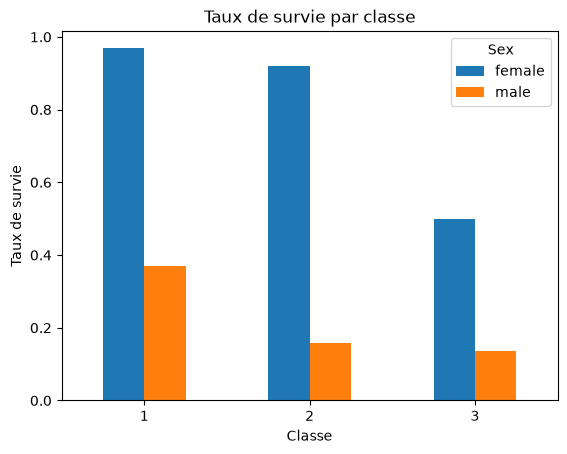

In [ ]:
# Écris ton code ici
titanic.pivot_table(index="Pclass", columns="Sex", values="Survived").plot.bar(rot=0, title="Taux de survie par classe", ylabel="Taux de survie", xlabel="Classe")

### ✏️ 8.2 — Âge des survivants et des décédés

Superpose, sur le **même graphique**, l'histogramme des âges des **décédés** et celui des **survivants**.

- Utilise les **âges d'origine** : garde seulement les passagers dont l'âge n'était pas manquant (`AgeManquant` vaut `False`), sinon les âges médians ajoutés en 2.4 déformeraient la répartition.
- Trace deux `.plot.hist(...)` l'un après l'autre, dans la même cellule : ils se dessinent sur le même graphique.
- Pour nommer l'axe et donner un titre au graphique, ajoute à la fin `plt.xlabel("âge")` et `plt.title("…")` : avec deux histogrammes, on passe par `plt` (matplotlib) plutôt que par les réglages de `.plot`.
- `alpha=0.5` rend les barres **semi-transparentes** pour voir les deux histogrammes à la fois ; `label="..."` donne le nom affiché dans la **légende**, que `plt.legend()` fait apparaître.

🧰 **Outils** : filtrage · `.plot.hist(bins=30, alpha=0.5, label="...")` · `plt.legend()` · `plt.xlabel(...)` · `plt.title(...)`

✅ **Résultat attendu** : deux histogrammes superposés, de couleurs différentes, avec une légende « décédés » / « survivants ».

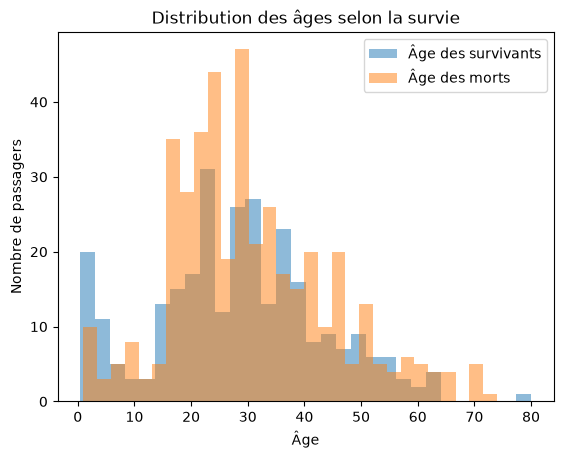

In [ ]:
# Écris ton code ici
#titanic.pivot_table(index="Pclass", columns="Sex", values="Survived").plot.bar(rot=0, title="Taux de survie par classe", ylabel="Taux de survie", xlabel="Classe")
titanic[titanic["Survived"] == 1]["Age"].plot.hist(bins=30, alpha=0.5, label="Âge des survivants")
titanic[titanic["Survived"] == 0]["Age"].plot.hist(bins=30, alpha=0.5, label="Âge des morts")
plt.title("Distribution des âges selon la survie")
plt.xlabel("Âge")
plt.ylabel("Nombre de passagers")
plt.legend()
plt.show()

### ✏️ 8.3 — Barres horizontales : survie par titre

Trace un **diagramme en barres horizontales** du taux de survie **par titre** (créé en 4.2), **trié** du plus petit au plus grand.

🧰 **Outils** : `groupby` · `mean` · `sort_values()` · `.plot.barh(title=...)`

✅ **Résultat attendu** : 5 barres ; `Mr` est la plus courte, `Mrs` la plus longue.

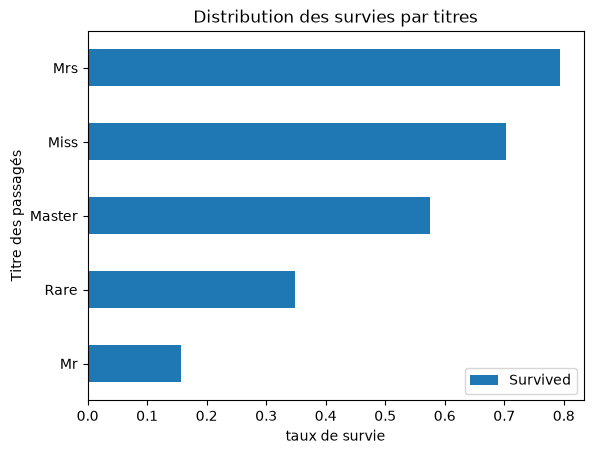

In [ ]:
# Écris ton code ici
titanic.groupby("title")["Survived"].mean().sort_values().plot.barh(title="Distribution des survies par titres")
plt.xlabel("taux de survie")
plt.ylabel("Titre des passagés")
plt.legend()
plt.show()

## 9. Sauvegarder et conclure

### ✏️ 9.1 — Sauvegarder le tableau nettoyé

Enregistre le tableau nettoyé et enrichi dans `titanic_propre.csv`, **sans l'index**. Puis relis-le et vérifie qu'il ne reste **aucune valeur manquante** dans `Age` et `Embarked`.

🧰 **Outils** : `to_csv("titanic_propre.csv", index=False)` · `pd.read_csv` · `[["Age", "Embarked"]]` · `isna().sum()`

✅ **Résultat attendu** : `Age 0` et `Embarked 0`.

In [ ]:
# Écris ton code ici
titanic.to_csv("titanic_propre.csv", index=False)
titanic_p = pd.read_csv("titanic_propre.csv")
display(titanic_p[["Age", "Embarked"]].isna().sum())

Age         0
Embarked    0
dtype: int64

### ✏️ 9.2 — Conclusion : qui a survécu ?
*Rédige 4 à 6 phrases qui répondent à la question fil rouge, en citant des chiffres obtenus plus haut.*

Ta réponse :

## 🧾 Ce que tu as ajouté à ta boîte à outils

| Nouveau geste | Code |
|---|---|
| Mesurer les manquants | `df.isna().mean()` |
| Remplir intelligemment | `fillna(...)` avec `mode()[0]`, `median()`, ou une valeur par groupe via `transform` |
| Garder la trace d'un traitement | colonne indicatrice (`AgeManquant`, `HasCabin`) |
| Manipuler du texte | `.str[0]`, `.str.extract(regex)`, `replace`, `where` |
| Découper en classes | `pd.cut(bins=..., labels=...)` |
| Agrégations nommées | `agg(nom=("col", "fonction"))` |
| Croiser deux variables | `pivot_table`, `crosstab(normalize=...)`, `unstack` |
| Joindre deux tables | `merge(left_on=..., right_on=..., how="left")` |

➡️ **Prochaine étape — Niveau 3 (TRANSPOSER) avec Olist** : une mission d'analyse des ventes d'une place de marché, à partir de plusieurs tables réelles, et c'est toi qui choisis tes outils.